# Лабораторная работа № 3. Классификация объектов нейронной сетью

## ( “Нейросетевые технологии обработки данных”)

### студентки 4-го курса 10-ой группы

### Ярмош Алеси

### Вариант 13

sklearn.datasets.load_digits 

10 классов, 64 признака, 1797
объектов (изображения цифр
8×8)

## Постановка задачи

Построить и обучить МСП-классификатор для датасета, указанного в вашем варианте,
продемонстрировать эффект переобучения без регуляризации и его подавление с помощью
L2-регуляризации и/или Dropout.

In [20]:
import numpy as np
import torch
import torch.nn as nn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score
import copy

In [21]:
torch.manual_seed(3)
np.random.seed(3)

In [22]:
X, y = load_digits(return_X_y=True, as_frame=True)
X, y

(      pixel_0_0  pixel_0_1  pixel_0_2  pixel_0_3  pixel_0_4  pixel_0_5  \
 0           0.0        0.0        5.0       13.0        9.0        1.0   
 1           0.0        0.0        0.0       12.0       13.0        5.0   
 2           0.0        0.0        0.0        4.0       15.0       12.0   
 3           0.0        0.0        7.0       15.0       13.0        1.0   
 4           0.0        0.0        0.0        1.0       11.0        0.0   
 ...         ...        ...        ...        ...        ...        ...   
 1792        0.0        0.0        4.0       10.0       13.0        6.0   
 1793        0.0        0.0        6.0       16.0       13.0       11.0   
 1794        0.0        0.0        1.0       11.0       15.0        1.0   
 1795        0.0        0.0        2.0       10.0        7.0        0.0   
 1796        0.0        0.0       10.0       14.0        8.0        1.0   
 
       pixel_0_6  pixel_0_7  pixel_1_0  pixel_1_1  ...  pixel_6_6  pixel_6_7  \
 0           0.0  

In [23]:
n_features = X.shape[1]

X.shape

(1797, 64)

In [24]:
# Проверка сбалансированности классов
counts = y.value_counts(normalize=True).sort_index()
print(counts)

n_classes = len(counts)

target
0    0.099054
1    0.101280
2    0.098497
3    0.101836
4    0.100723
5    0.101280
6    0.100723
7    0.099610
8    0.096828
9    0.100167
Name: proportion, dtype: float64


1. Описание датасета (источник – sklearn.datasets, число объектов, признаков, классов; баланс классов).

- 10 классов, 64 признака, 1797
объектов (изображения цифр
8×8)

- классы сбалансированы

Разделение на train, val, test

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=3)

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=3)

Стандартизация (обучаемая только на train)

In [26]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train).astype(np.float32)
X_val_s = scaler.transform(X_val).astype(np.float32)
X_test_s = scaler.transform(X_test).astype(np.float32)

In [27]:
Xtr = torch.tensor(np.array(X_train_s)); ytr = torch.tensor(np.array(y_train), dtype=torch.long)
Xval = torch.tensor(np.array(X_val_s)); yval = torch.tensor(np.array(y_val), dtype=torch.long)
Xtest = torch.tensor(np.array(X_test_s)); ytest = torch.tensor(np.array(y_test), dtype=torch.long)

Типичная архитектура: входной слой (по числу признаков) → один или несколько
скрытых слоёв с нелинейной активацией (ReLU – стандартный выбор для классификации,
в отличие от аппроксимации гладких функций в лабораторной работе 1, где предпочтительнее tanh) → выходной слой из K нейронов без явной активации внутри сети (PyTorch
1
nn.CrossEntropyLoss самостоятельно применяет softmax внутри функции потерь, поэтому сеть возвращает «сырые» логиты).

Пусть число нейронов на скрытых слоях будет равно n_features + K

In [28]:
class MLP(nn.Module):
    def __init__(self, n_in, n_hidden, n_classes, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(
            
        nn.Linear(n_in, n_hidden), nn.ReLU(),
        
        nn.Dropout(dropout),

        nn.Linear(n_hidden, n_hidden), nn.ReLU(),
        
        nn.Dropout(dropout), 
        
        nn.Linear(n_hidden, n_classes),
        )
    def forward(self, x):
        return self.net(x)

In [29]:
def train_model(weight_decay=0.0, epochs=300, hidden=n_classes+n_features, lr=0.01, dropout=0.0):
    torch.manual_seed(3)
    model = MLP(n_features, hidden, n_classes, dropout)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss()
    
    train_hist, val_hist = [], []
    best_val = float('inf')
    best_state = None
    best_epoch = -1
    
    for epoch in range(epochs):
        # ---- TRAIN ----
        model.train()
        opt.zero_grad()
        loss = loss_fn(model(Xtr), ytr)
        loss.backward()
        opt.step()
        
        # ---- VAL ----
        model.eval()
        with torch.no_grad():
            vloss = loss_fn(model(Xval), yval).item()
        
        train_hist.append(loss.item())
        val_hist.append(vloss)
        
        # ---- СОХРАНЯЕМ ЛУЧШЕЕ ----
        if vloss < best_val:
            best_val = vloss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            
    
    # ---- ВОССТАНАВЛИВАЕМ ЛУЧШИЕ ВЕСА ----
    model.load_state_dict(best_state)
    
    return model, train_hist, val_hist, best_epoch

In [30]:
models = {
    "baseline": {
        "config": {},
        'model': None,
        "results": {
            "train_hist": None,
            "val_hist": None,
        },
        'best_epoch': None
    },

    "l2": {
        "config": {
            "weight_decay": 1e-4,
        },
        'model': None,
        "results": {
            "train_hist": None,
            "val_hist": None,
        },
        'best_epoch': None
    },

    "dropout=0.1": {
        "config": {
            "dropout": 0.1,
        },
        'model': None,
        "results": {
            "train_hist": None,
            "val_hist": None,
        },
        'best_epoch': None
    },

    "dropout=0.3": {
        "config": {
            "dropout": 0.3,
        },
        'model': None,
        "results": {
            "train_hist": None,
            "val_hist": None,
        },
        'best_epoch': None
    },

    "dropout=0.5": {
        "config": {
            "dropout": 0.5,
        },
        'model': None,
        "results": {
            "train_hist": None,
            "val_hist": None,
        },
        'best_epoch': None
    }
}

In [31]:
import matplotlib.pyplot as plt

In [32]:
from IPython.display import Markdown, display

table = [
    '| Модель | Test accuracy | Train loss (last) | Val loss (last) | Min Val loss | Лучшая эпоха |',
    '|---|---:|---:|---:|---:|---:|'
]

baseline: test accuracy = 0.9578
train[-1]=0.00003 val[-1]=0.18646 val_min=0.14212 (эпоха 23)
Матрица ошибок (модель baseline):
[[45  0  0  0  0  0  0  0  0  0]
 [ 0 45  0  0  0  0  0  0  1  0]
 [ 0  0 43  1  0  0  0  0  0  0]
 [ 0  0  1 45  0  0  0  0  0  0]
 [ 0  0  0  0 45  0  0  0  0  0]
 [ 0  0  0  0  0 43  0  0  0  3]
 [ 1  0  0  0  0  0 44  0  0  0]
 [ 0  0  0  0  1  1  0 43  0  0]
 [ 0  2  1  2  0  2  1  0 35  0]
 [ 0  0  0  0  0  2  0  0  0 43]]
Лучшая эпоха 23


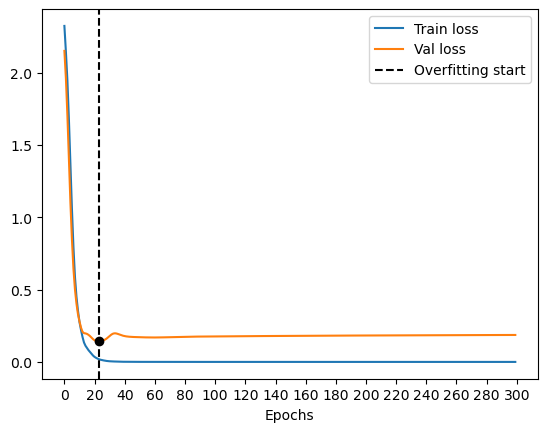

l2: test accuracy = 0.9800
train[-1]=0.00046 val[-1]=0.11035 val_min=0.11035 (эпоха 299)
Матрица ошибок (модель l2):
[[44  0  1  0  0  0  0  0  0  0]
 [ 0 46  0  0  0  0  0  0  0  0]
 [ 0  0 44  0  0  0  0  0  0  0]
 [ 0  0  0 46  0  0  0  0  0  0]
 [ 0  0  0  0 45  0  0  0  0  0]
 [ 0  0  0  0  0 44  0  0  0  2]
 [ 0  0  0  0  1  0 44  0  0  0]
 [ 0  0  0  0  0  0  0 44  0  1]
 [ 0  1  0  0  0  1  0  1 40  0]
 [ 0  0  0  0  0  1  0  0  0 44]]
Лучшая эпоха 299


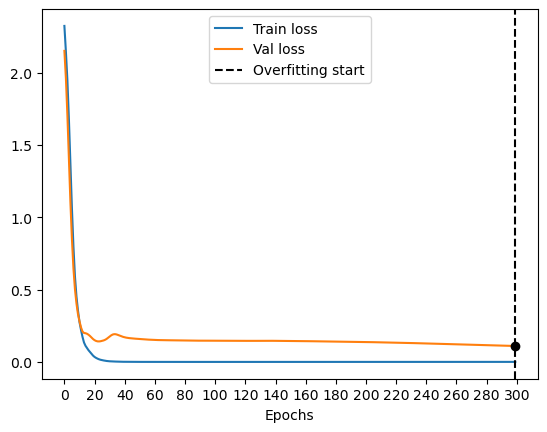

dropout=0.1: test accuracy = 0.9778
train[-1]=0.00032 val[-1]=0.16166 val_min=0.13698 (эпоха 213)
Матрица ошибок (модель dropout=0.1):
[[45  0  0  0  0  0  0  0  0  0]
 [ 0 46  0  0  0  0  0  0  0  0]
 [ 0  0 44  0  0  0  0  0  0  0]
 [ 0  0  0 46  0  0  0  0  0  0]
 [ 0  0  0  0 44  0  1  0  0  0]
 [ 0  0  0  0  0 43  0  0  0  3]
 [ 0  0  0  0  1  0 44  0  0  0]
 [ 0  0  0  0  0  0  0 44  0  1]
 [ 0  1  0  0  0  1  0  1 40  0]
 [ 0  0  0  0  0  1  0  0  0 44]]
Лучшая эпоха 213


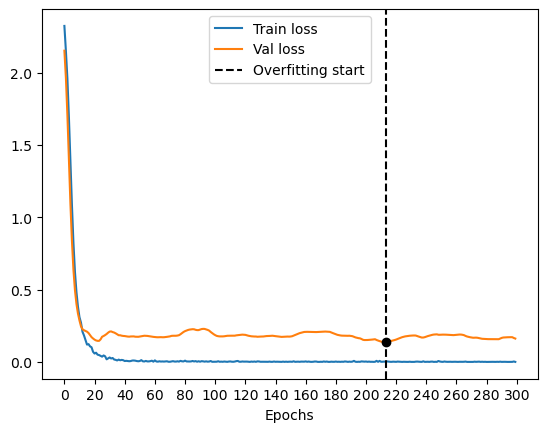

dropout=0.3: test accuracy = 0.9756
train[-1]=0.00632 val[-1]=0.12539 val_min=0.07916 (эпоха 257)
Матрица ошибок (модель dropout=0.3):
[[45  0  0  0  0  0  0  0  0  0]
 [ 0 46  0  0  0  0  0  0  0  0]
 [ 0  0 43  1  0  0  0  0  0  0]
 [ 0  0  0 46  0  0  0  0  0  0]
 [ 0  0  0  0 45  0  0  0  0  0]
 [ 0  0  0  0  0 43  0  0  0  3]
 [ 0  0  0  0  1  0 44  0  0  0]
 [ 0  0  0  0  0  0  0 44  0  1]
 [ 0  1  1  0  0  0  0  1 40  0]
 [ 0  0  0  0  0  2  0  0  0 43]]
Лучшая эпоха 257


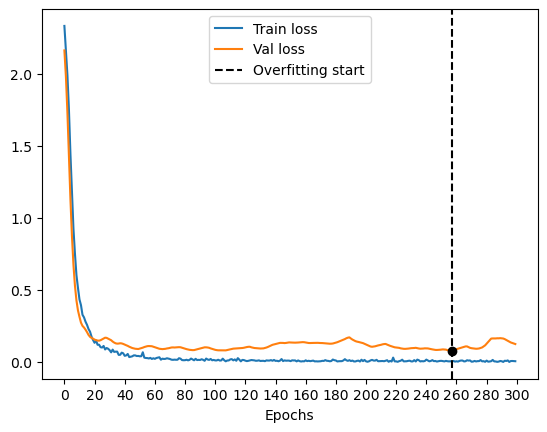

dropout=0.5: test accuracy = 0.9733
train[-1]=0.04567 val[-1]=0.17380 val_min=0.07823 (эпоха 101)
Матрица ошибок (модель dropout=0.5):
[[45  0  0  0  0  0  0  0  0  0]
 [ 0 46  0  0  0  0  0  0  0  0]
 [ 0  0 43  1  0  0  0  0  0  0]
 [ 0  0  0 46  0  0  0  0  0  0]
 [ 0  0  0  0 45  0  0  0  0  0]
 [ 0  0  0  0  0 43  0  0  0  3]
 [ 0  0  0  0  1  0 44  0  0  0]
 [ 0  0  0  0  0  0  0 44  0  1]
 [ 0  1  0  0  0  1  1  1 39  0]
 [ 0  0  0  0  0  2  0  0  0 43]]
Лучшая эпоха 101


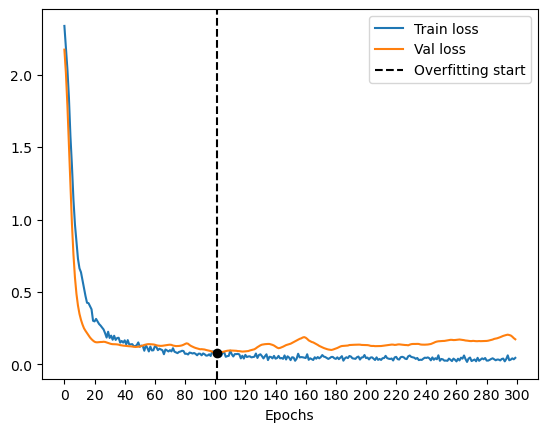

| Модель | Test accuracy | Train loss (last) | Val loss (last) | Min Val loss | Лучшая эпоха |
|---|---:|---:|---:|---:|---:|
| baseline | 0.9578 | 0.00003 | 0.18646 | 0.14231 | 23 |
| l2 | 0.9800 | 0.00046 | 0.11035 | 0.11064 | 299 |
| dropout=0.1 | 0.9778 | 0.00032 | 0.16166 | 0.13702 | 213 |
| dropout=0.3 | 0.9756 | 0.00632 | 0.12539 | 0.07967 | 257 |
| dropout=0.5 | 0.9733 | 0.04567 | 0.17380 | 0.07882 | 101 |

In [33]:
for model_name, model_dict in models.items():
    model_dict['model'], model_dict['results']['train_hist'], model_dict['results']['val_hist'], model_dict['best_epoch'] = train_model(
        **model_dict['config'])
    
    model, results = model_dict['model'], model_dict['results']
    model.eval()
    with torch.no_grad():
        pred = model(Xtest).argmax(dim=1).numpy()
    
    accuracy = accuracy_score(y_test, pred)

    train_hist = results['train_hist']
    val_hist = results['val_hist']
    train_last = train_hist[-1]
    val_last = val_hist[-1]
    
    print(f'{model_name}: test accuracy = {accuracy_score(y_test, pred):.4f}')
    print('train[-1]={:.5f} val[-1]={:.5f} val_min={:.5f} (эпоха {})'
    .format(results['train_hist'][-1], results['val_hist'][-1], min(results['val_hist']), int(np.argmin(results['val_hist']))))
    print(f'Матрица ошибок (модель {model_name}):')
    print(confusion_matrix(y_test, pred))
    
    best_epoch = model_dict['best_epoch']
    best_val = val_hist[best_epoch - 1]
    
    print(f'Лучшая эпоха {best_epoch}')
    
    table.append(
        f'| {model_name} '
        f'| {accuracy:.4f} '
        f'| {train_last:.5f} '
        f'| {val_last:.5f} '
        f'| {best_val:.5f} '
        f'| {best_epoch} |'
    )
    
    plt.plot(range(300), results['train_hist'], label='Train loss')
    plt.plot(range(300), results['val_hist'], label='Val loss')
    plt.scatter(best_epoch, results['val_hist'][best_epoch], color='black', zorder=10)
    plt.axvline(
        best_epoch,
        color='black',
        linestyle='--',
        zorder=5,
        label='Overfitting start'
    )
    plt.xticks(range(0, 301, 20))
    plt.legend()
    plt.xlabel('Epochs')
    plt.show()

display(Markdown('\n'.join(table)))

## Дополнительное задание

In [34]:
models = {
    "baseline": {
        "config": {},
        'model': None,
        "results": {
            "train_hist": None,
            "val_hist": None,
        },
    },

    "l2": {
        "config": {
            "weight_decay": 1e-4,
        },
        'model': None,
        "results": {
            "train_hist": None,
            "val_hist": None,
        },
    },

    "dropout=0.1": {
        "config": {
            "dropout": 0.1,
        },
        'model': None,
        "results": {
            "train_hist": None,
            "val_hist": None,
        },
    },

    "dropout=0.3": {
        "config": {
            "dropout": 0.3,
        },
        'model': None,
        "results": {
            "train_hist": None,
            "val_hist": None,
        },
    },

    "dropout=0.5": {
        "config": {
            "dropout": 0.5,
        },
        'model': None,
        "results": {
            "train_hist": None,
            "val_hist": None,
        },
    }
}

In [35]:
lambda_table = [
    '| Модель | Test accuracy | Gap btw train loss and val loss |',
    '|---|---:|---:|'
]

In [36]:
lambdas = [0, 1e-4, 1e-3, 1e-2, 1e-1]

In [37]:
lambda_models = {f'lambda={lam}': 
    {'config': {'weight_decay': lam}, 
     'accuracy': None,
     'gap': None} 
    for lam in lambdas}

In [38]:
for model_name, model_dict in lambda_models.items():
    mod, train_hist, val_hist = train_model(
        **model_dict['config'])
        
    model.eval()
    with torch.no_grad():
        pred = model(Xtest).argmax(dim=1).numpy()
    
    accuracy = accuracy_score(y_test, pred)
    model_dict['accuracy'] = accuracy
    
    model_dict['gap'] = val_hist[-1] - train_hist[-1]
    lambda_table.append(
        f'| {model_name} '
        f'| {accuracy:.4f} '
        f'| {model_dict['gap']:.4f} |'
    )

display(Markdown('\n'.join(lambda_table)))

ValueError: too many values to unpack (expected 3)

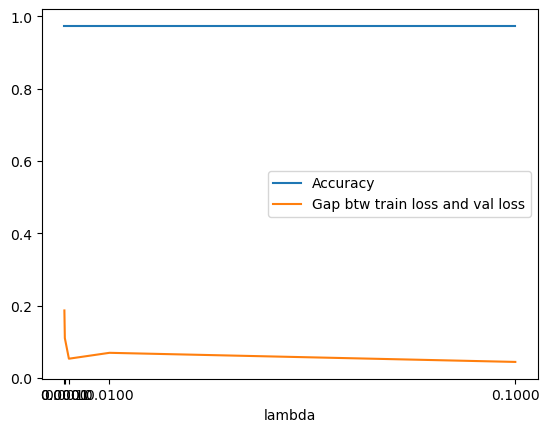

In [ ]:
plt.plot(lambdas, [model['accuracy'] for model in lambda_models.values()], label='Accuracy')
plt.plot(lambdas, [model['gap'] for model in lambda_models.values()], label='Gap btw train loss and val loss')
plt.xlabel('lambda')
plt.xticks(lambdas)
plt.legend()
plt.show()

## Контрольные вопросы к защите лабораторной работы
### 1. Почему для классификации используют кросс-энтропию, а не MSE в качестве функции потерь? Как это связано с softmax на выходном слое?

    Кросс-энтропию используют для классификации, потому что она оценивает вероятность правильного класса и обычно обеспечивает более полезные градиенты для обучения. Softmax преобразует логиты в распределение вероятностей, а кросс-энтропия измеряет, насколько это распределение соответствует истинным меткам. В PyTorch CrossEntropyLoss выполняет вычисления совместно, численно устойчивым способом.

### 2. Зачем нужно стратифицированное разбиение на train/test/val? Что может пойти не так при обычном случайном разбиении несбалансированного датасета?

    Стратифицированное разбиение сохраняет исходные пропорции классов во всех выборках. Это делают, чтобы не получилось так, что все объекты какого-то класса попали в одну из выборок, из-за чего оценка качества модели будет необъективна. 

### 3. Почему StandardScaler (или любое другое масштабирование) обучается только на
обучающей выборке, а не на всём датасете сразу?

    Это частный случай общего правила: любое преобразование данных, зависящее от статистик
    выборки, не должно «видеть» тестовые данные при своей настройке (иначе – утечка информации из теста в обучение)

### 4. Как по графикам train/val loss отличить переобучение от недообучения? Опишите характерный вид кривых в каждом случае.

    Переобучение -- сначала и train и val loss падают, а затем val loss начинает расти при маленьком train loss. Это значит, что модель заучила тренировочную выборку. Недообучение -- и train loss и val loss остаются на достаточно высоком уровне. Значит, модель плохо обучилась, и ее еще рано использовать для инференса. При нормальном обучении и train loss и val loss уменьшаются и стабилизируются около минимума, разрыв между ними небольшой.

### 5. Объясните механизм L2-регуляризации (weight decay): почему штраф за большие веса снижает переобучение?

    L2-регуляризация защищает модель от переобучения, прибавляя к функции потерь веса по формуле L=Ldata​+λi∑​wi2​. Таким образом, модель штрафуется за заучивание конкретных примеров из обучающей выборки.

### 6. Чем Dropout отличается от L2-регуляризации по механизму действия? В чём смысл масштабирования 1/(1 − p) в инвертированном Dropout?

    Dropout отключает нейрон с вероятностью p. Т.к. это меняет среднее значение активации слоя, было принято масштабировать нейроны, которые не подверглись отключению на множитель 1 / (1-p). Таким образом, мат ожидание остается p * 0 + (1-p) * h / (1-p) == h, как и без dropout.

### 7. В каком случае accuracy – ненадёжная метрика качества классификации и что стоит использовать вместо неё (или вместе с ней)?

    В случае дисбаланса классов. Тогда accuracy может быть завышенным, если модель будет каждый раз предсказывать мажорный класс. Вместе с ней следует использовать Precision, Recall, F1-score, confusion matrix.

### 8. Что показывает матрица ошибок, чего не показывает единственное число accuracy?

    Матрица ошибок показывает, реальный класс объекта (номер строки), предсказанный класс (номер столбца). Таким образом можно наглядно определить ошибки модели.